<a href="https://colab.research.google.com/github/nestorveas/Tarea3_gf0657/blob/main/Tarea3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 3: Distribución de las ASADAS de Costa Rica

Autor: Néstor Veas Ayala
Carné: A13865

## Introducción
El trabajo en el curso *[Programación en SIG (GF-0657)](https://gf0657-programacionsig.github.io/2026-ii/)* busca generar respuestas respecto a diferentes datos de las diferentes Asociaciones Administradoras de Acueducto y Alcantarillado Rural, comúnmente llamadas *ASADAS*, en Costa Rica.

Esta figura legal es una de las cuatro que Costa Rica tiene autorizada para brindar el servicio público de abastecimiento de agua potable y saneamiento, siendo las otras tres el propio Instituto Costarricense de Acueductos y Alcantarillados (AyA), Municipalidades, y la Empresa de Servicios Públicos de Heredia (ESPH).


### ¿Qué son las ASADAS?

Este tipo de acueductos abastecen a casi un 25% de la población en más de 1400 entidades a nivel nacional [(AyA, 2020)](https://dspaceaya.igniteonline.la/server/api/core/bitstreams/0b743fb2-d3ec-4cf0-a66d-d10ece8ab3ef/content), y tienen una importancia especial ya que son administradas de manera comunal. Lo anterior implica que los miembros de las Juntas Directivas de cada ASADA son personas de la o las comunidades abastecidas, y que los cobros por el servicio, asi como el mantenimiento y ampliaciones del acueducto, las compras y actividades son gestionadas por cada ASADA.

Es importante indicar que las ASADAS son supervisadas y tuteladas a nivel normativo y técnico por el **(AyA)**

### Datos respecto a las ASADAS

A continuación se presenta la base de datos que se utilizará para trabajar y generar respuestas respecto a la información de las distintas ASADAS del país para el año 2024. La fuente de esta base de datos es el Sistema de Apoyo para la Gestión de Asadas (SAGA) del AyA y para su utilización se revisó el [Manual de Usuario-Entrada y Salida del SAGA](https://pnud-conocimiento.cr/wp-content/uploads/2021/07/MANUAL-DE-ENTRADA-Y-SALIDA-DEL-SAGA.pdf).

Esta infomación incluye datos relevantes a saber:

1. Código de cada ASADA
2. Cantidad de servicios abastecidos
3. Número de habitantes abastecidos
4. Cantidad de hidrantes en cada ASADA
5. Nombre oficial de cada ASADA

### Preguntas

Para entender y contextualizar el presente de las ASADAS en Costa Rica la información nos ayudará a responder algunas dudas, por ejemplo:

- ¿Cuales provincias del país tienen la mayor cantidad de ASADAS?
- ¿Cuántas ASADAS hay en cada cantón de Costa Rica?
- ¿Donde se ubica, cuantos servicios da y qué población abastece cada ASADA a nivel nacional?
  
### Información base

Para realizar este trabajo se utilizaron dos capas espaciales de información, a saber:

1. Capa de cantones del país, la cual se encuentra dentro del [Nodo IGN Cartografía 1:5mil CO](https://www.snitcr.go.cr/ico_servicios_ogc_info?k=bm9kbzo6OTM=&nombre=IGN%20Cartograf%C3%ADa%201:5mil%20CO) del Sistema Nacional de Información Territorial (*SNIT*).
- Formato:.gpkg
- Tipo: Vectorial, polígonos
- Sistema de Coordenadas: WGS84
- Información relevante: Nombre de cantón, código de cantón, nombre de provincia, área de cantón.

2. Capa de oficinas de ASADAS del Costa Rica. Se obtuvo del Sistema de Apoyo para la Gestión de Asadas (*SAGA*) del AyA.
- Formato:.shp
- Tipo: Vectorial, puntos
- Sistema de Coordenadas: CRTM05
- Información relevante: Nombre de ASADA, calificación de ASADA, población abastecida, número de servicios.

## Carga de bibliotetecas y capas de información

El primer paso es importar todas las extensiones necesarias para poder ejecuta el trabajo. Algunas de estas extensiones que además se han visto en el curso son pandas, geopandas, folium y plotly.



In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
import plotly.express as px
from IPython.display import display
import matplotlib
import rasterio
import folium
import math
import os
from folium import plugins
import numpy as np
import branca.colormap as cm

# Direcciones de los directorios de datos en el repositorio del curso
TAREA3 = "https://github.com/nestorveas/Tarea3_gf0657/raw/refs/heads/main/"

Seguidamente hacemos la carga de las dos capas de información, a partir de las cuales se hará todo el trabajo posterior. Como se indicó previamente, estas son la capa de cantones y de puntos de oficinas de ASADAS de Costa Rica.

In [2]:
asadas = gpd.read_file(TAREA3 + "Asadas.gpkg")
cantones = gpd.read_file(TAREA3 + "cantones-2020-simplificados.gpkg")

Posteriormente procedemos a revisar las propiedades de ambas capas

In [3]:
# Tipo del objeto, SRC y tipos de geometría
print(type(asadas))
print(asadas.shape)
print(asadas.crs)
print(asadas.geom_type.value_counts())

<class 'geopandas.geodataframe.GeoDataFrame'>
(1372, 44)
EPSG:5367
Point    1372
Name: count, dtype: int64


In [4]:
# Tipo del objeto, SRC y tipos de geometría
print(type(cantones))
print(cantones.shape)
print(cantones.crs)
print(cantones.geom_type.value_counts())

<class 'geopandas.geodataframe.GeoDataFrame'>
(82, 11)
EPSG:4326
Polygon         78
MultiPolygon     4
Name: count, dtype: int64


Es importante que para hacer la operación espacial entre capas, los cantones deben reproyectarse al sistema de coordenadas CRTM05, el mismo en el que se encuentra la capa de oficinas de ASADAS

In [5]:
cantones_cr05 = cantones.to_crs(5367)

Posterior a este paso, revisamos ambas capas para ver qué información tienen y de qué tipo.

In [6]:
asadas.head()

,Región,Ente_Opera,PROVINCIA,Cantón,DISTRITO,F______DAT,Teléfono_,Fax,Correo,Dirección,...,F______COM,IDEO,PKENTEOPER,Comunidade,Cantidad_F,Total_Caud,Caudal_Req,Aprobados_,URL_IMAGEN,geometry
0,Región Central Este,"00719-2014_EL HUMO DE PEJIBAYE DE JIMENEZ, CAR...",CARTAGO,JIMENEZ,PEJIBAYE,None,None,None,asadaelhumo@gmail.com,None,...,None,00719-2014,103,None,0,0,0,0,None,POINT (531457 1086443)
1,Región Huetar Norte,"00015-2014_SAN JOSE (PIZOTE) DE UPALA, ALAJUELA",ALAJUELA,UPALA,SAN JOSE O PIZOTE,None,83054684,None,asadasanjose@hotmail.com,DEL PUENTE METALICO 400 M NORTE A UN COSTADO D...,...,None,00015-2014,1536,"CAMELIA, CARTAGO SUR, COLONIA EVAGELICA, DELIC...",1,43,37,20,None,POINT (375817.87 1212246.91)
2,Región Huetar Norte,"00023-2014_EL PROGRESO DE SAN JOSE DE UPALA, A...",ALAJUELA,UPALA,SAN JOSE O PIZOTE,None,87186088,None,acueductosanboscoprogreso@gmail.com,COSTADO SUR DE LA ESCUELA EL PROGRESO DE UPALA,...,None,00023-2014,1537,"PROGRESO, VALLE BONITO, SAN BOSCO,",2,3,2,2,None,POINT (364679.07 1215110.7)
3,Región Pacífico Central,00029-2014_SAN MIGUEL DE PIEDADES SUR DE SAN R...,ALAJUELA,SAN RAMON,PIEDADES SUR,None,24472953,24472953,asadasanmiguel.ps@hotmail.com,300 METROS NORTE DE LA PLAZA DE DEPORTES DE SA...,...,None,00029-2014,1538,"CALLE JIMENEZ, SAN MIGUEL CENTRO, BAJO BARRANT...",6,14,3,3,None,POINT (443344.28 1118805.74)
4,Región Pacífico Central,"00334-2014_SAN JOSE DEL HIGUERON, LA ANGOSTURA...",ALAJUELA,SAN RAMON,SANTIAGO,None,7217 984,None,asadasjh@gmail.com,DEL CRUCE DE SAN RAMON22 KILOMETROS SOBRE LA R...,...,None,00334-2014,1539,"DANZA DE MARIPOSAS, LA ANGOSTURA, DANZAS DE MA...",4,6,1,0,None,POINT (436037.82 1108432.77)


In [7]:
cantones.head()

,gmlid,objectid,cod_catalo,cod_canton,canton,ori_toponi,area,cod_provin,provincia,version,geometry
0,limitecantonal_5k.1,1.0,160104,610,Corredores,Tiene su origen en el topónimo del río Corredo...,623.61,6,Puntarenas,20200429,"POLYGON ((-82.9356 8.42366, -82.95353 8.41391,..."
1,limitecantonal_5k.2,2.0,160104,607,Golfito,"Se debe a la forma que presenta el litoral, d...",1753.42,6,Puntarenas,20200429,"MULTIPOLYGON (((-83.46678 8.68886, -83.46655 8..."
2,limitecantonal_5k.3,3.0,160104,608,Coto Brus,De origen indígena las palabras Coto (couto) B...,944.24,6,Puntarenas,20200429,"POLYGON ((-82.90501 8.77425, -82.90654 8.77489..."
3,limitecantonal_5k.4,4.0,160104,605,Osa,"En recuerdo del cacique Osa, que en los inicio...",1932.03,6,Puntarenas,20200429,"POLYGON ((-83.83977 9.25543, -83.83642 9.25533..."
4,limitecantonal_5k.5,5.0,160104,603,Buenos Aires,El nombre se le dio por la brisa constante que...,2382.94,6,Puntarenas,20200429,"POLYGON ((-83.32144 9.38418, -83.31946 9.38414..."


Ya que la capa de ASADAS tiene mucha información y no toda es relevante para este trabajo, se procede a "limpiar" la información que se desea mantener. Para ello se crea un nuevo geodataframe de nombre "asadas_limpio".

In [8]:
asadas_limpio = asadas[["Ente_Opera", "DISTRITO", "IDEO", "Este", "Norte", "Tipo_Admin", "Calificaci", "Servicios_", "Poblacion_", "geometry"]]
asadas_limpio.head()

,Ente_Opera,DISTRITO,IDEO,Este,Norte,Tipo_Admin,Calificaci,Servicios_,Poblacion_,geometry
0,"00719-2014_EL HUMO DE PEJIBAYE DE JIMENEZ, CAR...",PEJIBAYE,00719-2014,531457.00,1086443.00,ASADA,C,0,0,POINT (531457 1086443)
1,"00015-2014_SAN JOSE (PIZOTE) DE UPALA, ALAJUELA",SAN JOSE O PIZOTE,00015-2014,375817.87,1212246.91,ASADA,A,2433,8515,POINT (375817.87 1212246.91)
2,"00023-2014_EL PROGRESO DE SAN JOSE DE UPALA, A...",SAN JOSE O PIZOTE,00023-2014,364679.07,1215110.70,ASADA,B,165,577,POINT (364679.07 1215110.7)
3,00029-2014_SAN MIGUEL DE PIEDADES SUR DE SAN R...,PIEDADES SUR,00029-2014,443344.28,1118805.74,ASADA,B,235,822,POINT (443344.28 1118805.74)
4,"00334-2014_SAN JOSE DEL HIGUERON, LA ANGOSTURA...",SANTIAGO,00334-2014,436037.82,1108432.77,ASADA,B,107,374,POINT (436037.82 1108432.77)


### Al menos una operación espacial

Al tener toda la información base lista, el primer paso es hacer una operación espacial. En este caso se hace un *spatial join*, donde la capa que se mantiene es la de puntos de oficinas de ASADAS, y a ella se le añade la información seleccionada de la capa de cantones para que cada oficina tenga el código de cantón, cantón y provincia a la que pertenece.

In [9]:
#Uso de la funcion sjoin
#En que cantón está cada asada

asadas_canton = gpd.sjoin(
    asadas_limpio,
    cantones_cr05[["cod_canton", "canton", "provincia", "geometry"]], #Solo esas lineas porque no ocupo todas, si me traigo la geometria porque es importante para la forma del shape
    how="left",
    predicate="within"
)


### Al menos una tabla

A partir de la operación anterior, generamos el primer apartado que se solicita para esta Tarea, la cual sería una tabla de las ASADAS del país donde además se observa el cantón y la provincia a la que pertenecen.

In [10]:
asadas_canton

,Ente_Opera,DISTRITO,IDEO,Este,Norte,Tipo_Admin,Calificaci,Servicios_,Poblacion_,geometry,index_right,cod_canton,canton,provincia
0,"00719-2014_EL HUMO DE PEJIBAYE DE JIMENEZ, CAR...",PEJIBAYE,00719-2014,531457.00,1086443.00,ASADA,C,0,0,POINT (531457 1086443),22,304,Jiménez,Cartago
1,"00015-2014_SAN JOSE (PIZOTE) DE UPALA, ALAJUELA",SAN JOSE O PIZOTE,00015-2014,375817.87,1212246.91,ASADA,A,2433,8515,POINT (375817.87 1212246.91),80,213,Upala,Alajuela
2,"00023-2014_EL PROGRESO DE SAN JOSE DE UPALA, A...",SAN JOSE O PIZOTE,00023-2014,364679.07,1215110.70,ASADA,B,165,577,POINT (364679.07 1215110.7),80,213,Upala,Alajuela
3,00029-2014_SAN MIGUEL DE PIEDADES SUR DE SAN R...,PIEDADES SUR,00029-2014,443344.28,1118805.74,ASADA,B,235,822,POINT (443344.28 1118805.74),49,202,San Ramón,Alajuela
4,"00334-2014_SAN JOSE DEL HIGUERON, LA ANGOSTURA...",SANTIAGO,00334-2014,436037.82,1108432.77,ASADA,B,107,374,POINT (436037.82 1108432.77),44,602,Esparza,Puntarenas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1367,05193-2023_KALVERY -VOLCANCITO,VALLE DE LA ESTRELLA,05193-2023,539000.00,1200000.00,ASOCIACION DE DESARROLLO INDIGENA,D,0,0,POINT (539000 1200000),69,702,Pococí,Limón
1368,05194-2023_ADI DE CONTE BURICA,PAVON,05194-2023,539000.00,1200000.00,ASOCIACION DE DESARROLLO INDIGENA,D,0,0,POINT (539000 1200000),69,702,Pococí,Limón
1369,05195-2023_SAN JUAN NORTE Y SUR DE TURRIALBA,TURRIALBA,05195-2023,533339.21,1092514.92,ASADA,D,0,0,POINT (533339.21 1092514.92),23,305,Turrialba,Cartago
1370,05196-2023_EL PROGRESO DE SANTA ANA,POZOS,05196-2023,539000.00,1200000.00,ASADA,C,0,0,POINT (539000 1200000),69,702,Pococí,Limón


### Al menos un gráfico

Para el segundo apartado solicitado, se realizó un gráfico de ASADAS por provincia. Para lograrlo se inició con la tabla supra, utilizando la función *groupby* y haciendo la agrupación por provincia, utilizando la función *size* para que sumara todas las ASADAS que correspondían a la misma provincia y diera como resultado una lista, la cual se nombró *asadas_provincia*

In [11]:
# Asadas por provincia, para el gráfico
asadas_provincia = asadas_canton.groupby("provincia").size().rename("asadas")



#asadas_provincia=asadas_limpio.groupby("Provincia")[["Servicios_abastecidos", "Poblacion_abastecida"]].sum()

asadas_provincia

,asadas
provincia,
Alajuela,321
Cartago,129
Guanacaste,281
Heredia,41
Limón,130
Puntarenas,207
San José,263


A partir del listado, se generó un dataframe con los mismos valores utilzando el comando *to_frame* y ordenando los datos de manera descendiente.

In [12]:
asadas_provincia_df=asadas_provincia.to_frame().sort_values("asadas",ascending=False).reset_index()

asadas_provincia_df



,provincia,asadas
0,Alajuela,321
1,Guanacaste,281
2,San José,263
3,Puntarenas,207
4,Limón,130
5,Cartago,129
6,Heredia,41


Finalmente, se genera el gráfico de Cantidad de ASADAS por provincia en el país.

In [13]:
# Generación del Gráfico 1

grafico1 = px.bar(
    asadas_provincia_df.sort_values("asadas"),
    x="provincia",
    y="asadas",
    color_discrete_sequence=["#1316B6"],
    title="Gráfico 1: Cantidad de ASADAS por Provincia, 2024",
    labels={"provincia": "Provincia ", "asadas": "Número de Asadas "},
    text_auto=",.0f", #para que se vean los datos en cada gráfico
)

grafico1.show()

El resultado muestra a la provincia de Heredia como la que menos ASADAS incluye, solo 41. Lo anterior se entiende ya que esta provincia es la única que tiene los cuatro tipos de operadores de agua potable y saneamiento autorizados, a saber la Empresa de Servicios Públicos de Heredia (ESPH), municipalidades (como el caso de Barva, Santa Bárbara, Santo Domingo, Belén, Flores), el AyA (que cubre el cantón de San Pablo) y las propias ASADAS.

La gran mayoría del sector urbano de la provincia está abastecido por la ESPH, el AyA y las Municipalidades mencionadas. Si bien existen algunas ASADAS en sectores cercanos a la parte urbana, la mayoría se encuentran en los sectores más rurales y alejados de la provincia, especialmente en el cantón de Sarapiquí; aunque curiosamente son ASADAS de gran extensión y cantidad de abonados (como la ASADA de Horquetas y sus más de 5.000 servicios), por lo que su cantidad total es baja.

Contrariamente, la provincia con más ASADAS es la de Alajuela. En esta provincia, un sector de la parte urbana de la ciudad de Alajuela es abastecida por el AyA, y la otra por la Municipalidad. De igual forma, los cascos urbanos de Zarcero, Naranjo, Poás, Grecia, Ciudad Quesada y Upala son abastecidos por las Municipalidades respectivas. Sin embargo, una gran cantidad de poblados cercanos a los cascos urbanos de estos municipios, así como sectores rurales de fuerte crecimiento como La Fortuna, Pital, Santa Rosa de Pocosol, Muelle y Florencia de San Carlos, Guatuso y Santa Cecilia de Upala se han desarrollado a partir de acueductos rurales, esta cultura hizo que en muchos casos haya muchas ASADAS en áreas relativamente pequeñas; un caso ejemplar es el poblado de Aguas Zarcas, que si bien tiene su ASADA, la misma está rodeada por más de 5 acueductos de menor tamaño, cuando todos ellos podrían fusionarse en uno solo.

Asimismo, las provincias de Alajuela, Guancaste y San José (las tres que tienen mayor cantidad de ASADAS) tienen la particularidad de que muchos de sus acueductos tienen pozos como fuente principal de recurso hídrico. Históricamente, es muy común que un pozo abastezca a una comunidad, y a partir del mismo se haya desarrollado una ASADA, mientras que para otro pozo cercano se generó otra ASADA y así sucesivamente. En la actualidad la creación de nuevas ASADAS se ha regulado mucho para evitar muchas ASADAS pequeñas, pero se mantienen muchas que se crearon previamente.

### Un mapa estático

Con la información anterior en mente, se procedió a generar una imágen que muestra de manera espacial la ubicación de las oficinas de las ASADAS a nivel nacional, teniendo un nivel más alto de precisión, pasando de provincias a cantones. Para ello se utilizó la herramienta *.subplots* y se utilizó la capa de cantones del país en el sistema de coordenadas CRTM05, así como la capa de ASADAS del país.  

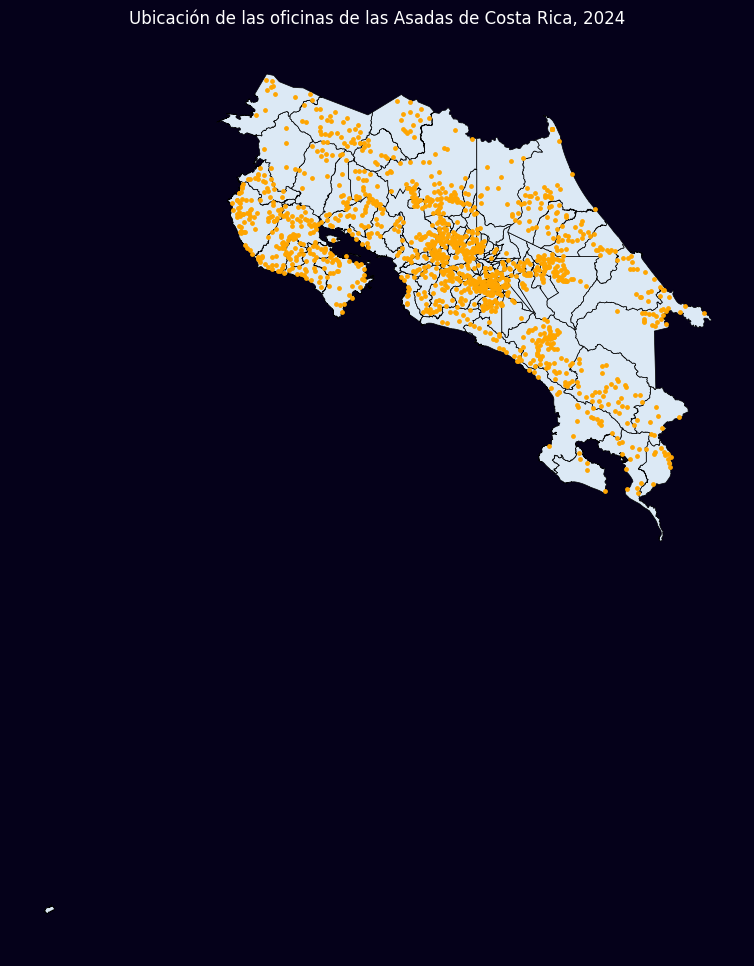

In [14]:
# el "fig" es el lienzo y el ax son los ejes del mapa, donde se dibujan los elementos
fig, ax = plt.subplots(figsize=(12, 12))

cantones_cr05.plot(ax=ax, color="#DCE9F5", edgecolor="black", linewidth=0.5)
asadas_limpio.plot(ax=ax, color="orange", markersize=6, legend=True, label="Oficinas de las Asadas")

fig.patch.set_facecolor("#05011A")

ax.set_title("Ubicación de las oficinas de las Asadas de Costa Rica, 2024")
ax.title.set_color("white")
ax.set_axis_off()

plt.show()

El mapa muestra como los acueductos comunales están repartidos por todo el país, pero con una fuerte concentración en la periferia de la GAM, los cantones de la península de Nicoya, la zona norte y la zona sur. La mayoría de estos casos son comunidades predominantemente rurales.

### Un mapa web interactivo

Para el producto final, se tuvieron que hacer varios pasos antes de generar el mapa.

Primero, se creó la tabla *conteo_asadas*, donde se sumaron la cantidad de ASADAS, población abastecida y servicios para cada cantón del país según la tabla *asadas_canton*, que se obtuvo originalmente. Un paso similar al que se hizo cuando se calculó la cantidad de ASADAS por provincia.

In [15]:
#Primero generamos el dataframe con la información que necesitamos para el mapa

conteo_asadas = asadas_canton.groupby("canton").agg(
    total_asadas=("Ente_Opera", "count"),
    serv_totales=("Servicios_", "sum"),
    pob_total=("Poblacion_", "sum")
).reset_index()

conteo_asadas

,canton,total_asadas,serv_totales,pob_total
0,Abangares,24,3153,11030
1,Acosta,28,4549,15916
2,Alajuela,39,17835,62416
3,Alajuelita,6,921,3222
4,Alvarado,3,315,1101
...,...,...,...,...
70,Turrialba,62,17670,61834
71,Turrubares,16,1563,5468
72,Upala,34,12886,45094
73,Vázquez de Coronado,1,336,1176


Seguidamente, a esta tabla se le unió la información de las columnas *cod_canton*, *canton* y *provincia* de la tabla de *cantones*. Para ello se utilizó la herramienta *.merge* y como llave común para unir ambas tablas se usó la columna *canton*. El resultado fue una nueva tabla de nombre *asadas_canton_df*.

Para evitar que en cantones sin ASADAS, sin servicios o sin población abastecida hubiera algún problema para la interpretación de los comandos, se procedió también a llenar los espacios con valores *NNA* con el valor de cero (0) con la herramienta *.fillna*, así como a pasar los valores esas tres columnas a números enteros con el comando *.astype*.

In [16]:
asadas_canton_df = cantones[["cod_canton", "canton", "provincia"]].merge(
    conteo_asadas,
    on="canton",
    how="left"
)

In [17]:
asadas_canton_df[["total_asadas", "serv_totales", "pob_total"]] = (
    asadas_canton_df[["total_asadas", "serv_totales", "pob_total"]].fillna(0).astype(int)
)

asadas_canton_df

,cod_canton,canton,provincia,total_asadas,serv_totales,pob_total
0,610,Corredores,Puntarenas,13,4782,16736
1,607,Golfito,Puntarenas,16,5836,20422
2,608,Coto Brus,Puntarenas,8,4425,15487
3,605,Osa,Puntarenas,22,6090,21311
4,603,Buenos Aires,Puntarenas,39,6054,21184
...,...,...,...,...,...,...
77,215,Guatuso,Alajuela,13,6549,22919
78,214,Los Chiles,Alajuela,15,4489,15710
79,501,Liberia,Guanacaste,6,635,2222
80,213,Upala,Alajuela,34,12886,45094


Posteriormente, se procedió a crear un geodataframe llamado *cantones_wgs84*, el cual tiene la información base de la capa de cantones, a la cual se le unió la información generada en el paso anterior. Con este paso se obtuvo una base de datos espacial con la geometría de los polígonos de los cantones del país, así como la información de cantidad de ASADAS, población y servicios para cada uno de ellos.

Para efectos de una mejor comprensión, se procedió a renombrar las columnas *canton* y *total_asadas* a nombres más elegantes, que son los que finalmente se proyectarán en el mapa. Para ello se creó el geodataframe *nombres_mapa* donde también se mantuvieron las filas y columnas de información previa.

In [18]:
cantones_wgs84 = cantones.merge(asadas_canton_df, on="canton", how="left")

cantones_wgs84

,gmlid,objectid,cod_catalo,cod_canton_x,canton,ori_toponi,area,cod_provin,provincia_x,version,geometry,cod_canton_y,provincia_y,total_asadas,serv_totales,pob_total
0,limitecantonal_5k.1,1.0,160104,610,Corredores,Tiene su origen en el topónimo del río Corredo...,623.61,6,Puntarenas,20200429,"POLYGON ((-82.9356 8.42366, -82.95353 8.41391,...",610,Puntarenas,13,4782,16736
1,limitecantonal_5k.2,2.0,160104,607,Golfito,"Se debe a la forma que presenta el litoral, d...",1753.42,6,Puntarenas,20200429,"MULTIPOLYGON (((-83.46678 8.68886, -83.46655 8...",607,Puntarenas,16,5836,20422
2,limitecantonal_5k.3,3.0,160104,608,Coto Brus,De origen indígena las palabras Coto (couto) B...,944.24,6,Puntarenas,20200429,"POLYGON ((-82.90501 8.77425, -82.90654 8.77489...",608,Puntarenas,8,4425,15487
3,limitecantonal_5k.4,4.0,160104,605,Osa,"En recuerdo del cacique Osa, que en los inicio...",1932.03,6,Puntarenas,20200429,"POLYGON ((-83.83977 9.25543, -83.83642 9.25533...",605,Puntarenas,22,6090,21311
4,limitecantonal_5k.5,5.0,160104,603,Buenos Aires,El nombre se le dio por la brisa constante que...,2382.94,6,Puntarenas,20200429,"POLYGON ((-83.32144 9.38418, -83.31946 9.38414...",603,Puntarenas,39,6054,21184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
77,limitecantonal_5k.78,78.0,160104,215,Guatuso,Dos versiones: 1- Los indigenas vivían cerca d...,752.84,2,Alajuela,20200429,"POLYGON ((-84.80557 10.85185, -84.80307 10.850...",215,Alajuela,13,6549,22919
78,limitecantonal_5k.79,79.0,160104,214,Los Chiles,Dos versiones: 1-Por una gran plantación de ch...,1332.71,2,Alajuela,20200429,"POLYGON ((-84.66639 11.07246, -84.60604 11.038...",214,Alajuela,15,4489,15710
79,limitecantonal_5k.80,80.0,160104,501,Liberia,El origen del nombre del cantón se remonta a 1...,1442.17,5,Guanacaste,20200429,"POLYGON ((-85.4714 10.96502, -85.4692 10.96521...",501,Guanacaste,6,635,2222
80,limitecantonal_5k.81,81.0,160104,213,Upala,Voz indígena del náhualt que significa: sobre ...,1592.67,2,Alajuela,20200429,"POLYGON ((-85.24049 11.06368, -85.23818 11.063...",213,Alajuela,34,12886,45094


In [19]:
nombres_mapa = cantones_wgs84.rename(columns={
    "canton": "Cantón",
    "total_asadas": "ASADAS en el canton"
})

Para seguir las recomendaciones dadas en el curso, antes de generar el mapa interactivo se procedió a estandarizar la capa de puntos de las oficinas de ASADAS al sistema de coordenadas WGS84. Con esto, ambas capas están en el mismo sistema de referencia y están listas para ser utilizadas en el mapa.

In [20]:
asadas_wgs84 = asadas_canton.to_crs(4326)

El producto final es generar el mapa interactivo. Para ello primero se establece donde se ubicará el centro del cuadrante del mapa a generar.

Seguidamente, se establecen manualmente los cortes a partir de los cuales se harán los bloques de colores, los cantones dentro de cada bloque tendrán un color diferente.

Luego se inicia el *mapa* con el comando *.explore*, y se llama a la capa de polígonos de los cantones con la información de las ASADAS, población y servicios en cada uno (*nombres_mapa*), se establece el mapa que estará de fondo (*ESRI.WorldGraycanvas*) y la columna sobre la cual se harán las coropletas (*Asadas en el canton*).

Posteriormente se completan los parámetros que tendrá el mapa de coropletas, es decir la cantidad de cortes en la simbología, el color, lo que se mostrará cuando el puntero pase sobre cada cantón, el título de la simbología, el punto central del mapa y el nivel de zoom del mapa proyyectado.

Después de este paso se procede a incluir la capa de puntos de las oficinas de las ASADAS (*asadas_wgs84*), se incluyen los parámetros de la simbología como el tamaño y color de los puntos de cada oficina, también los datos que se despliegan cuando el puntero pasa por cada oficina y el nombre que se desea que aparezca para cada dato. Esta información se añade al mapa de coropletas mediante el comando *.addto*.

Finalmente, se procede a generar y desplegar el mapa resultante.

In [21]:
CENTRO_CR = (9.75, -84.15)

In [22]:
cortes = [0, 10, 25, 50]

mapa= nombres_mapa.explore(tiles= "ESRI.WorldGraycanvas", column="ASADAS en el canton") #column genera un mapa de coropletas con el dato que se seleccione
mapa = nombres_mapa.explore(
    column="ASADAS en el canton", scheme="UserDefined", classification_kwds={"bins":cortes}, k=5, cmap="YlOrRd",
    tooltip=["Cantón", "ASADAS en el canton"], aliases= ["Cantón", "ASADAS en el cantón"], tiles="Esri.WorldGrayCanvas",
    style_kwds={"color": "white", "weight": 0.7}, missing_kwds={"color": "#E6E6E6"},
    legend_kwds={"caption": "Número de Asadas en cada cantón, 2024"},
    name="Número de Asadas", location=CENTRO_CR, zoom_start=8
)

folium.GeoJson(asadas_wgs84, name="Oficinas de Asadas",
               marker=folium.CircleMarker(radius=2, color="black", fill=True, fill_opacity=0.8),
               tooltip=folium.GeoJsonTooltip(fields=["Ente_Opera", "canton", "Servicios_", "Poblacion_"], aliases=["Nombre de la ASADA", "Cantón", "Número de Servicios", "Población abastecida"])).add_to(mapa)
folium.LayerControl().add_to(mapa) #el .add_to se usa para juntarlo con el mapa previamente generado

mapa

## Conclusiones

La mayor cantidad de ASADAS se encuentran en la provincia de Alajuela con 321, seguida de Guanacaste y San José. Por el contrario, la provincia con menos ASADAS es Heredia, donde solamente existen 41 de estas organizciones communales.

El cantón con más ASADAS del país es San Carlos con 77, pero hay una gran cantidad de cantones que tienen 50 o más ASADAS como Turrialba, Pérez Zeledón, Puntarenas, Nicoya y Santa Cruz. Todos ellos tienen centros urbanos de mediano tamaño, pero están rodeados de una gran cantidad de comunidades rurales que utilizaron fuentes cercanas para abastecerse de agua potable, lo cual generó las actuales ASADAS.

Del lado opuesto, hay 7 cantones del país que no tienen ninguna ASADA dentro de sus límites. Es importante indicar que al ser una base de datos con información previa al año 2024, no se incluyen dentro de los mismos los nuevos cantones de Monteverde y Puerto Jiménez, aunque ambos tienen ASADAS bajo sus antiguas denominaciones de Puntarenas y Golfito.

Finalmente, el mapa interactivo generado permite observar no solo cuantas ASADAS posee cada anton del país, si no que también ofrece información detallada de cada una de estas entidades, destacando su nombre, el cantón en el que se encuentra, la cantidad de servicios y población abastecida por cada una de ellas. Esta información puede ser revisada por el usuario para responder a estas preguntas.

## Bibliografía

Instituto Costarricense de Acueductos y Alcantarillados (AyA). (2020). *Agua para uso y consumo humano y saneamiento en Costa Rica al 2019: Brechas y desafíos al 2023*. Laboratorio Nacional de Aguas.

Instituto Costarricense de Acueductos y Alcantarillados (AyA). (2018). *Manual de Usuario - Entrada y Salidad del SAGA*. Sistema de Apoyo para la Gestión de Asadas (SAGA).

Sistema de Apoyo para la Gestión de Asadas (SAGA). 2024. *Base de datos de Asadas de Costa Rica*. Comunicación personal.


## Declaración de uso de asistentes de IA

Para el presente trabajo se utilizó apoyo del asistente de IA *Gemini*, el asistente fue utilizado para consultas puntuales y también brindó sugerencias para completar el texto que se estaba programando. Sin embargo, el texto completo y la gran mayoría de la programación de este trabajo fue realizado por el autor, así como la revisión de los resultados y gráficos que aquí se presentan.